# Fair Value Model

In [1]:
import os
import sys
import pickle
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
data_path = os.path.join(repo_path, "data")

In [3]:
src_path = os.path.join(repo_path, "src")
sys.path.append(src_path)
from FairValueModel import FairValue

In [4]:
rtn_path = os.path.join(data_path, "PrepData", "Rtn.parquet")
df_rtn   = (pd
    .read_parquet(path = rtn_path, engine = "pyarrow")
    .loc[lambda x: (x.hedge != "no") & (x.asset == "etf") & (x.fa_ticker == "ANGL") & (x.fi_ticker == "HYG")]
    .set_index("date")
    .assign(spread = lambda x: 0.5 * (x.fa_rtn - x.fi_rtn))
    [["spread", "hedge"]])

# Getting Backtests

In [5]:
path = os.path.join(data_path, "Models", "FullSampleLinearModel.pkl")
with open(path, "rb") as f: fs_ols = pickle.load(f)

In [6]:
df_is_fs = (fs_ols
    .resid
    .to_frame(name = "resid")
    .assign(lag_resid = lambda x: x.resid.shift())
    .merge(right = df_rtn, how = "inner", on = ["date"])
    .assign(signal_rtn = lambda x: -np.sign(x.lag_resid) * x.spread)
    .reset_index()
    .assign(
        model        = "fs_ols",
        sample_group = "in_sample"))

In [7]:
path = os.path.join(data_path, "Models", "InSampleLinearModel.pkl")
with open(path, "rb") as f: is_ols = pickle.load(f)

In [8]:
df_prep = FairValue()._prep_data()

In [9]:
y, X = df_prep.spread, df_prep.drop(columns = ["spread"])

In [10]:
X_       = sm.add_constant(X)
y_pred   = is_ols.predict(X_)
df_resid = (df_prep
    [["spread"]]
    .assign(
        y_pred    = y_pred,
        resid     = lambda x: x.spread - x.y_pred,
        lag_resid = lambda x: x.resid.shift())
    [["lag_resid"]])

In [11]:
slice_year = FairValue().slice_year

In [12]:
df_train_test = (df_resid
    .merge(right = df_rtn, how = "inner", on = ["date"])
    .reset_index()
    .assign(
        year         = lambda x: x.date.dt.year,
        signal_rtn   = lambda x: -np.sign(x.lag_resid) * x.spread,
        model        = "train_test_split",
        sample_group = lambda x: np.where(x.year <= slice_year, "in_sample", "out_sample")))

In [13]:
df_tmp1 = (df_train_test
    [["date", "hedge", "signal_rtn", "model", "sample_group"]])

df_tmp2 = (df_is_fs
    [["date", "hedge", "signal_rtn", "model", "sample_group"]])

df_ols = pd.concat([df_tmp1, df_tmp2])

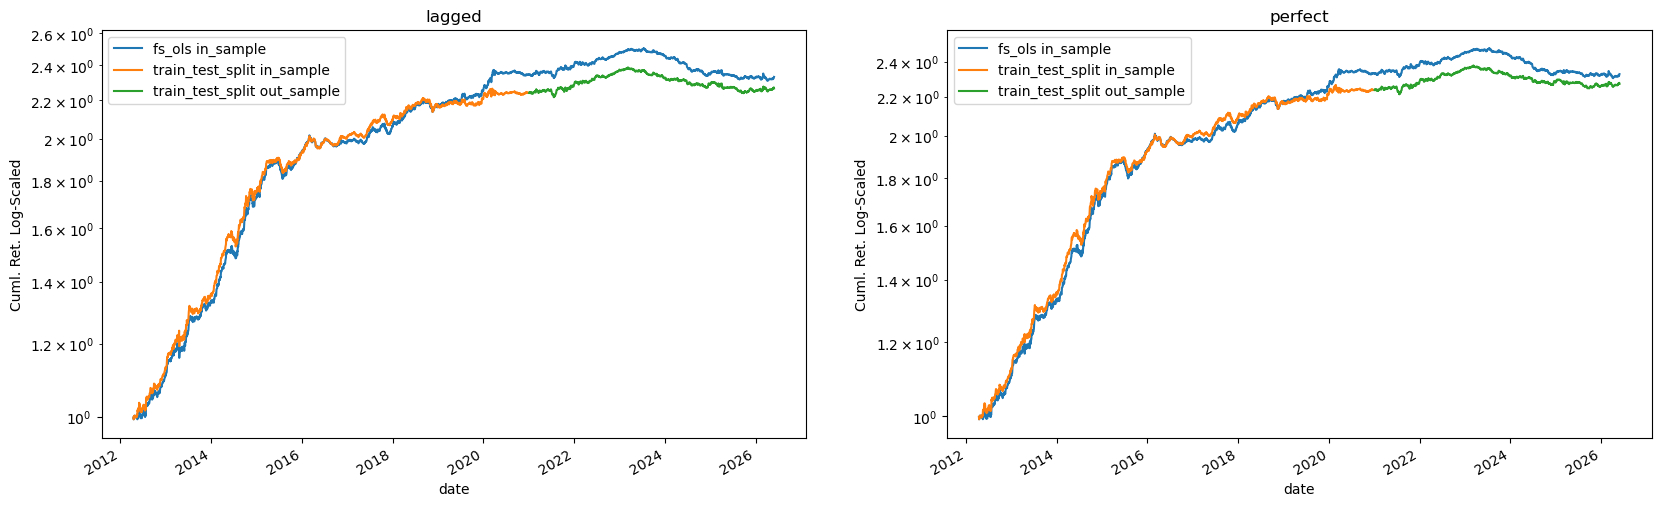

In [14]:
group_vars = df_ols.hedge.drop_duplicates().sort_values().to_list()
fig, axes  = plt.subplots(ncols = len(group_vars), figsize = (20,6))

for group_var, ax in zip(group_vars, axes.flatten()): 

    df_tmp = (df_ols
        .loc[lambda x: x.hedge == group_var]
        .assign(name = lambda x: x.model + " " + x.sample_group))

    df_namer = (df_tmp
        [["date", "model", "name"]])

    df_longer = (df_tmp
        .pivot(index = "date", columns = "model", values = "signal_rtn")
        .apply(lambda x: np.cumprod(1 + x))
        .reset_index()
        .melt(id_vars = "date")
        .merge(right = df_namer, how = "inner", on = ["date", "model"])
        .rename(columns = {"name": ""})
        .pivot(index = "date", columns = "", values = "value")
        .plot(
            ax     = ax,
            logy   = True,
            ylabel = "Cuml. Ret. Log-Scaled",
            title  = group_var))

In [15]:
path = os.path.join(data_path, "Models", "InSampleRandomForest.pkl")
with open(path, "rb") as f: rf_model = pickle.load(f)

In [16]:
y_pred = rf_model.predict(X)

In [17]:
df_resid = (df_prep
    [["spread"]]
    .assign(
        y_pred    = y_pred,
        resid     = lambda x: x.spread - x.y_pred,
        lag_resid = lambda x: x.resid.shift())
    [["lag_resid"]])

In [18]:
df_fs = (df_resid
    .merge(right = df_rtn, how = "inner", on = ["date"])
    .reset_index()
    .assign(
        year         = lambda x: x.date.dt.year,
        signal_rtn   = lambda x: -np.sign(x.lag_resid) * x.spread,
        model        = "fs_model",
        sample_group = lambda x: np.where(x.year <= slice_year, "in_sample", "out_sample"),
        name         = lambda x: x.hedge + " " + x.sample_group))

In [19]:
df_prep = (df_fs
    .pivot(index = "date", columns = "hedge", values = "signal_rtn")
    .apply(lambda x: np.cumprod(1 + x))
    .reset_index()
    .melt(id_vars = "date"))

<Axes: xlabel='date'>

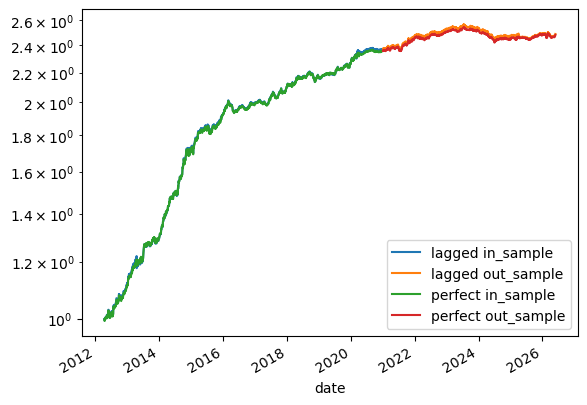

In [20]:
(df_fs
    [["date", "name", "hedge"]]
    .merge(right = df_prep, how = "inner", on = ["date", "hedge"])
    .rename(columns = {"name": ""})
    .pivot(index = "date", columns = "", values = "value")
    .plot(logy = True))

In [1]:
import os;
print(os.getcwd())

A:\GitHub\FallenAngelRiskPremia\notebook
